In [1]:
import torch, torch.nn as nn
print(torch.__version__)

2.11.0+cu130


In [2]:
import math, numpy as np, pandas as pd, torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["churn"] = (df["Churn"] == "Yes").astype(int)

num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat = ["Contract", "InternetService", "PaymentMethod",
        "PaperlessBilling", "Partner", "Dependents", "TechSupport"]

X = pd.get_dummies(df[num + cat], columns=cat, dtype=int)
y = df["churn"]

X_tv, X_test, y_tv, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

X_tr, X_val, y_tr, y_val = train_test_split(
    X_tv, y_tv, test_size=0.25, random_state=42, stratify=y_tv
)

med = X_tr["TotalCharges"].median()
for d in (X_tr, X_val, X_test):
  d["TotalCharges"] = d["TotalCharges"].fillna(med)

sc = StandardScaler().fit(X_tr)

Xtr = torch.tensor(sc.transform(X_tr), dtype=torch.float32)
Xval = torch.tensor(sc.transform(X_val), dtype=torch.float32)
Xtest = torch.tensor(sc.transform(X_test), dtype=torch.float32)

ytr = torch.tensor(y_tr.values, dtype=torch.float32).unsqueeze(1)
yval = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)
ytest = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

print(med)
print(X_tr.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())
print(Xtr.shape, ytr.shape, round(ytr.mean().item(), 4), round(yval.mean().item(), 4))
print(Xtest.shape, Xval.shape)
print("churners: train", int(y_tr.sum()), "| validation", int(y_val.sum()), "| test", int(y_test.sum()))

1385.3
0 0 0
torch.Size([4225, 23]) torch.Size([4225, 1]) 0.2653 0.2654
torch.Size([1409, 23]) torch.Size([1409, 23])
churners: train 1121 | validation 374 | test 374


In [6]:
import torch, torch.nn as nn, math
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score

loss_fn = nn.BCEWithLogitsLoss()

In [17]:
#Cell F2: a mini-batch training loop
def val_stats(model):
  model.eval()
  with torch.no_grad():
    lg = model(Xval)
    l = loss_fn(lg, yval).item()
    p = torch.sigmoid(lg).numpy()
  return round(l, 4), round(roc_auc_score(yval.numpy(), p), 4)

def train_mb(model, opt, bs, epochs, show, seed=42):
  g = torch.Generator().manual_seed(seed)
  dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=bs, shuffle=True, generator=g)
  for e in range(1, epochs + 1):
    model.train()
    tot = 0
    for xb, yb in dl:
      opt.zero_grad()
      l = loss_fn(model(xb), yb)
      l.backward()
      opt.step()
      tot += l.item() * len(yb)
    if e in show:
      print(e, round(tot / len(Xtr), 4), *val_stats(model))
  return model

In [20]:
print("batches per epoch:", len(DataLoader(TensorDataset(Xtr, ytr), batch_size=64)), "| rows in the last batch:", len(Xtr) % 64)
torch.manual_seed(42)
A = nn.Linear(23, 1)
train_mb(A, torch.optim.Adam(A.parameters(), lr=0.01), 64, 20, (1, 5, 10, 20))

batches per epoch: 67 | rows in the last batch: 1
1 0.5638 0.4986 0.829
5 0.4288 0.4323 0.831
10 0.4211 0.4334 0.8315
20 0.4194 0.4323 0.8327


Linear(in_features=23, out_features=1, bias=True)

Compare with Day 14: model A needed 300 FULL-batch steps to reach val AUC 0.8325. Here it reaches 0.829 after ONE epoch (67 updates).
Write one sentence: why does mini-batch training
learn so much faster per epoch? (Count the updates.)
- Because mini-batch training uses epoch for one full pass through every training row. Each batch makes one update, of all the weights while Day 14 model A needed 300 epochs Full-batch steps to reach val AUC 0.8325 because it will train on all rows at once, one update per epoch. With 4,225 rows and batch size 64, one epoch is 67 updates. Full batch (Day 14) is 1 update per epoch. After 1 epoch the mini-batch model already made 67 steps, and that’s why it reaches 0.829. The Day 14 model needed 300 steps to reach 0.8325.

Write one sentence: the last batch has only 1 row. What would drop_last=True do here, and
would you use it?
- drop_last=True will drop the lasst remaining row and I would drop the last row because a batch of 1 row gives a very noisy gradient estimate.


In [23]:
#Cell F3: batch size
for bs in (32, 256, 4225):
  torch.manual_seed(42)
  A = nn.Linear(23, 1)
  print("batch size", bs, "| updates per epoch", math.ceil(4225 / bs))
  train_mb(A, torch.optim.Adam(A.parameters(), lr=0.01), bs, 10, (10,))

batch size 32 | updates per epoch 133
10 0.4212 0.434 0.8317
batch size 256 | updates per epoch 17
10 0.4357 0.4418 0.8312
batch size 4225 | updates per epoch 1
10 0.6143 0.6177 0.7986


Write two sentences:

(a) What does batch size 4225 (full batch) give you after 10 epochs, and why?
- the performance get worse where it gives higher train loss(0.6143) and high validation loss(0.6177) and a much lower validation AUC (0.7986) compared to the smaller batch sizes. With a batch size of 4225, one epoch is 1 update. After 10 epochs the model has only made 10 updates, which isn’t enough to learn. With batch size 32, it makes 133 updates per epoch, so about 1,330 updates in the same 10 epochs. The full-batch gradient is the most accurate, but it takes far too few steps.

(b) What is the trade-off of a small batch size like 32? (Hint: each batch is a small noisy sample of the data, so each step is a noisier estimate of the true gradient. Also, more steps per epoch means more Python overhead.)
- The trade-off of a small batch size like 32 is that it introduces noisy, gradient steps and higher Python loop overhead. Batch size 32 makes 133 updates per epoch (4225 ÷ 32, rounded up), a small batch gives many noisy steps per epoch, so it learns faster per epoch, and the price is noisier gradients and more Python loop overhead. A large batch gives accurate gradients, but few steps due to making an update changes all the weights.

In [24]:
#Cell F4: learning rate (use plain SGD so you see the effect clearly)
for lr in (0.0001, 0.001, 0.01, 0.1, 1.0, 10.0):
  torch.manual_seed(42)
  A = nn.Linear(23, 1)
  print("SGD lr", lr, end=" -> ")
  train_mb(A, torch.optim.SGD(A.parameters(), lr=lr), 64, 10, (10,))

SGD lr 0.0001 -> 10 0.7129 0.7182 0.6197
SGD lr 0.001 -> 10 0.6167 0.6215 0.7751
SGD lr 0.01 -> 10 0.4511 0.4574 0.8283
SGD lr 0.1 -> 10 0.4207 0.4331 0.8314
SGD lr 1.0 -> 10 0.4501 0.4429 0.8282
SGD lr 10.0 -> 10 2.2689 1.5435 0.6538


what goes wrong at lr 0.0001?
- At a learning rate of 0.0001, the step size is too small, causing the model to learn incredibly slowly and remain havent travelled far in 10 epochs which causes in high losses (0.7129) with a low AUC (0.6197) after 10 epochs. With enough epochs it would get there; it is slow, not stuck.

what goes wrong at lr 10?
- At a learning rate of 10.0, the steps are too large, which causes the optimizer to aggressively overshoot the minimum, destabilizing training and making the loss explode to 2.2689.

which lr is best here?
- The best lr is 0.1 because which achieves the lowest validation loss (0.4331) and the highest validation AUC (0.8314)

what happens to it at lr 1.0?
- The steps become slightly too wide, causing the validation loss to begin rising again (0.4429) as it begins to overshoot the ideal solution.

In [27]:
#Cell F5: optimizers on the network with a hidden layer (model B), 20 epochs, batch 64
mk = lambda: nn.Sequential(nn.Linear(23, 16), nn.ReLU(), nn.Linear(16, 1))
opts = {
    "SGD lr.01": lambda p: torch.optim.SGD(p, lr=0.1),
    "SGD+momentum lr.01": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
    "Adam lr.001": lambda p: torch.optim.Adam(p, lr=0.001),
    "AdamW lr.001 wd.01": lambda p: torch.optim.AdamW(p, lr=0.001, weight_decay=0.01)
}
for name, make_opt in opts.items():
  torch.manual_seed(42)
  B = mk()
  print(name, end=" -> ")
  train_mb(B, make_opt(B.parameters()), 64, 20, (20,))

SGD lr.01 -> 20 0.4119 0.4359 0.8297
SGD+momentum lr.01 -> 20 0.4123 0.4359 0.8299
Adam lr.001 -> 20 0.4142 0.4348 0.8302
AdamW lr.001 wd.01 -> 20 0.4143 0.4346 0.8303


(a) Why do momentum and Adam both beat plain SGD at the same step budget?
- Plain SGD evaluates each batch completely independently, causing it to stall on flat plateaus or bounce erratically in noisy directions. Momentum resolves this by adding a fraction of the previous step's direction to the current step, which helps it accelerate through flat zones. Adam takes this further by dynamically adapting the learning rate for each individual parameter based on how frequently it changes, allowing it to navigate complex loss landscapes and converge onto a better solution within the exact same number of steps.

(b) Adam and AdamW are almost identical here. Why would you still choose AdamW as the default?
- AdamW fixes how L2 regularization (weight decay) is mathematically calculated. In standard Adam, weight decay is mixed directly into the moving averages of the gradients, which unintentionally distorts how the adaptive learning rates are scaled. AdamW decouples the weight decay completely, subtracting it directly from the weights at the end of the step. Even though they perform identically on this small 20-epoch run, you choose AdamW as your permanent default because it generalizes significantly better when models scale up in size, preventing weights from growing too large over longer training windows.

In [34]:
#Cell F6: one function that runs ONE epoch, for training or for validation
def run_epoch(model, loader, opt=None):
  train = opt is not None
  model.train() if train else model.eval()
  tot, n = 0.0, 0
  ps, ys = [], []
  with torch.set_grad_enabled(train):
    for xb, yb in loader:
      logits = model(xb)
      loss = loss_fn(logits, yb)
      if train:
        opt.zero_grad()
        loss.backward()
        opt.step()
      tot += loss.item() * len(yb)
      n += len(yb)
      ps.append(torch.sigmoid(logits).detach())
      ys.append(yb)
  p = torch.cat(ps).numpy().ravel()
  y_ = torch.cat(ys).numpy().ravel()
  return tot / n, roc_auc_score(y_, p)

why do we multiply by len(yb) and divide by n at the end, instead of averaging the batch losses?
- 66 batches have 64 rows and the last has 1. If you averaged the 67 batch losses, that one-row batch would count as much as a 64-row batch. Multiplying each batch loss by its size and dividing by the total rows n gives the true average loss per row over the whole epoch.

what does torch.set_grad_enabled(False) save during validation?
- computational memory (VRAM/RAM) and processing time by completely disabling the calculation and storage of gradients

In [35]:
#Cell F7: the full loop, with a histor
def train_model(model, opt, train_loader, val_loader, epochs):
  hist ={"train_loss": [], "val_loss": [], "val_auc": []}
  for e in range(1, epochs + 1):
    tl, _ = run_epoch(model, train_loader, opt)
    vl, va = run_epoch(model, val_loader)
    hist["train_loss"].append(tl)
    hist["val_loss"].append(vl)
    hist["val_auc"].append(va)
  return hist

In [36]:
g = torch.Generator().manual_seed(42)
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(Xval, yval), batch_size=256, shuffle=False)
torch.manual_seed(42)
C = nn.Sequential(nn.Linear(23, 64), nn.ReLU(), nn.Linear(64, 1))
h = train_model(C, torch.optim.Adam(C.parameters(), lr=0.01), train_loader, val_loader, 40)
for e in (1, 5, 10, 20, 30, 40):
  print(e, round(h["train_loss"][e - 1], 4), round(h["val_loss"][e - 1], 4), round(h["val_auc"][e - 1], 4))

best = int(np.argmin(h["val_loss"])) + 1
print("best epoch by validation loss:", best, round(min(h["val_loss"]), 4))

1 0.4443 0.4415 0.8282
5 0.4215 0.4461 0.8293
10 0.413 0.4444 0.8278
20 0.4068 0.4485 0.8217
30 0.3982 0.4426 0.8249
40 0.4039 0.4545 0.8166
best epoch by validation loss: 11 0.4367


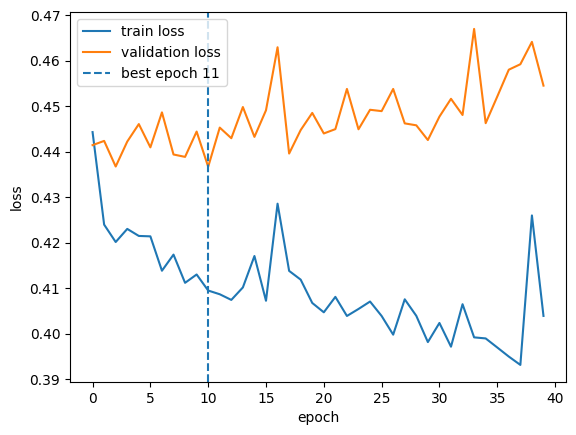

In [33]:
#Cell F8: the loss curve
import matplotlib.pyplot as plt
plt.plot(h["train_loss"], label="train loss")
plt.plot(h["val_loss"], label="validation loss")
plt.axvline(best - 1, linestyle="--", label=f"best epoch {best}")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

Where does overfitting start, and how do you see it?
- After epoch 11 it starts to overfitting (marked 11 as best) because after thatt, thte validation loss keep increasing to the point 0.4367 → 0.4545, from the best epoch 11 to epoch 40.

Why is the validation curve jagged, and what would smooth it?
- Because the mini-batch steps is made of noise and variance between data batches during training updates. to smooth it out, increase the batch size to optimal to reduce the gradient noise, and a smaller learning rate will make weight updates less aggressive, and averaging the curve over a few epochs (a moving average) will smooth the displayed curve.

Why stop at the best epoch and not at epoch 40?
- Because at epoch 11, that where the model achieves the highest validation auc(0.8278) and second lowest validation loss(0.4444).After the best epoch the model gets worse on unseen data (in my run, val loss 0.4367 → 0.4545 and AUC 0.8293 → 0.8166), even though its train loss keeps improving. It is memorizing the training rows. Stopping at the best epoch gives the model that generalizes best, and it saves training time.

**Training a neural network means choosing a few settings (epoch, batch size, learning rate, optimizer), running a training loop and a validation loop, and reading the loss curve to see whether the model is learning or memorising.**

- **Epoch:** one full pass in which the model sees every training row once.

- **Batch and batch size:** a batch is the chunk of rows processed before one weight update. Updates per epoch = ceil(rows ÷ batch size), for example 4225 rows with batch size 64 gives 67 updates (the last batch has only 1 row).

- **Learning rate (LR):** the size of each weight update, `w -= lr × gradient`. It is a hyperparameter that I choose, not something the model learns. Too big overshoots or diverges, too small learns slowly.

- **Training loop vs validation loop:** the training loop uses `model.train()` and repeats `zero_grad()`, `backward()`, `step()`, so the weights change. The validation loop uses `model.eval()` and `torch.no_grad()` with no weight updates, so it measures the model on rows it has never trained on.

- **Optimizers:** SGD takes a plain step along the gradient. Adam adapts the step size for each weight and uses momentum. AdamW is Adam with weight decay applied separately.

- **Loss curve:** train loss and validation loss plotted per epoch. When train loss keeps falling but validation loss turns upward, the model is overfitting.

- **My result:** on model C (23 → 64 → 1), validation loss was best at epoch 11 (0.4367), then rose to 0.4545 by epoch 40 while train loss kept falling. Validation AUC stayed near 0.829 at best and slipped to 0.8166. Stopping at the best epoch is early stopping (Day 17).

- **Bug I caught:** my validation AUC was computed on only the last 129 rows, because `ps, ys` were emptied every batch. The fix was to create the lists before the loop and call `torch.cat` after it. Lesson: when a metric looks too good, check how it is computed.

** Explain without notes, 1 to 3 sentences each: **

- For a dataset of 4,225 rows with a batch size of 64, your model will perform exactly 67 updates per epoch. This calculation is found by dividing the total rows by the batch size (4225 / 64 = 66.015) and rounding up to account for the final remaining row.

- The learning rate controls the size of each weight update. If it is too big, the model will overshoot, if it is too small thhe model will learns slowly.

- The difference between training loop and a validation loop is the training loop uses model.train(), and repeats zero_grad(), backward(), and step() so the weight changes while a validation loop uses model.eval() and no_grad() with no weight update because it measures the model on rows it has never trained on.

- Adam is easier to use than plain SGD because plain SGD requires manual tuning because it applies a single, fixed step size to all weights, whereas Adam is adaptive and automatically handles the step size for each individual weight based on its historical gradients.

- A validation loss that rises while the train loss falls means your model is overfitting. It has stopped learning helpful, general rules and is instead hard-memorising the specific quirks, noise, and accidental patterns of the training rows.